
<div style="background-color: lightgreen; color: black; padding: 20px; box-sizing: border-box; width: 99%;">

👋 <b>¡Hola! Soy Dot, tu revisor IA.</b>

🎉 <b>¡Felicidades! Has aprobado tu proyecto.</b>

¡Excelente trabajo al completar esta tarea! Corregiste la prueba de chi-cuadrado para la fuente de tráfico utilizando únicamente los conteos observados, y tus conclusiones y tu resumen ejecutivo ahora coinciden con los resultados corregidos, con una recomendación clara y orientada al negocio a favor de la página B. Para futuros proyectos, vuelve a ejecutar todo el notebook antes de entregarlo para que cada salida guardada coincida con tu código, imprime los valores p en notación científica y indica claramente cuando un resultado es estadísticamente significativo pero de tamaño modesto. ¡Sigue con el gran trabajo!

Si experimentas alguna dificultad o error, no dudes en contactar a nuestro equipo de soporte haciendo clic en el ícono de chat en la esquina superior derecha o escribiéndonos a [helpme@tripleten.com](mailto:helpme@tripleten.com).

<hr style="margin-top: 20px; margin-bottom: 20px;">

<details>
<summary><b style="cursor: pointer;">💡 Haz clic aquí para ver cómo leer mis comentarios (Leyenda de colores)</b></summary>
<div style="margin-top: 15px;">
A continuación encontrarás mis comentarios. <b>Te pido amablemente que no los muevas, modifiques ni elimines</b>.

Puedes encontrar mis comentarios resaltados en recuadros verdes, amarillos o rojos como estos:

<div class="alert alert-block alert-success">
Éxito. Todo se ha realizado correctamente.
</div>

<div class="alert alert-block alert-warning">
Observaciones. Algunas recomendaciones.
</div>

<div class="alert alert-block alert-danger">
Por corregir. El bloque requiere algunas correcciones.
</div>
</div>
</details>

</div>


# Experimento A/B en página de inicio

El objetivo de este proyecto es evaluar un **experimento A/B** realizado en una página de inicio (landing page) con versiónes **A y B** para apoyar una **decisión de negocio basada en datos**.

---

El archivo `landing_experiment.csv` contiene información de usuarios expuestos a dos versiones de la página de inicio (landing page) dentro del experimento A/B. Incluye región, dispositivo, fuente de tráfico, tipo de usuario, conversión y gasto.

El análisis sigue una lógica clara y progresiva:

1. 🔍 Explorar y validar los datos.

2. 💰 Comparar el **gasto promedio** por usuario entre la página A y B.

3. 🎯 Comparar la **tasa de conversión** entre la página A y B.

4. 🌐 Revisar **la relación entre la fuente de tráfico y la conversión**.

5. 👤 Revisar **la relación entre el tipo de usuario y la conversión**.

6. 📈 **Visualizar los resultados**: Respalda tus conclusiones mediante gráficos claros.

Se aplican **puebas estadísticas apropiados** para comparar las páginas y **recomendar qué versión es mejor**, justificando la decisión con datos.

## 🧩 Paso 1: Cargar y validar los datos

### 1.1 Carga de datos y vista rápida

In [113]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
from statsmodels.stats.proportion import proportions_ztest
from scipy.stats import chi2_contingency
from scipy.stats import levene


In [114]:
# cargar archivo
df = pd.read_csv('/datasets/landing_experiment.csv')

**Vista previa e información general del conjunto de datos**

In [115]:
# mostrar las primeras 5 filas
df.head()

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [116]:
# información general
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB


In [117]:
df['date'] = pd.to_datetime(df['date'])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   user_id         40000 non-null  object        
 1   date            40000 non-null  datetime64[ns]
 2   landing         40000 non-null  object        
 3   region          40000 non-null  object        
 4   dispositivo     40000 non-null  object        
 5   traffic_source  40000 non-null  object        
 6   user_type       40000 non-null  object        
 7   converted       40000 non-null  int64         
 8   gasto           40000 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(6)
memory usage: 2.7+ MB


✍️ **Comentario**: El dataframe contiene 40000 registros y 9 columnas. En la inspeccion inicial no se evidencia presencia de datos nulos. La columna 'date' se encontraba inicialmente como tipo de dato object; se convirtió a datetime para representar correctamente la información del tiempo analizado.

No se observan otros problemas de calidad durante esta revisión inicial.

<div class="alert alert-block alert-success">

Buen trabajo. Convertiste la columna de fecha a datetime y confirmaste el cambio al revisar nuevamente los tipos de las columnas. Tus notas sobre 40,000 registros, 9 columnas y ningún valor nulo coinciden con los resultados anteriores.

</div>

**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### 1.2 Análisis exploratorio y revisión de calidad de datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.


 **Variable `user_id`**  
 Verificar usuarios únicos

Se confirma  que se cuenta con 40000 usuarios unicos para el estudio.
 

In [118]:
print("Total de registros:", len(df))
print("Usuarios únicos:", df['user_id'].nunique())
print("Usuarios duplicados:", df['user_id'].duplicated().sum())

Total de registros: 40000
Usuarios únicos: 40000
Usuarios duplicados: 0


<div class="alert alert-block alert-success">

Bien hecho. Comparar el total de registros (40,000), los IDs únicos (40,000) y el conteo explícito de duplicados (0) respalda directamente tu afirmación sobre los usuarios únicos. La afirmación ahora está junto a su evidencia. Esto también respalda el supuesto de independencia en el que te apoyas en las pruebas posteriores.

</div>

In [119]:
df.groupby('landing').nunique()

,user_id,date,region,dispositivo,traffic_source,user_type,converted,gasto
landing,,,,,,,,
A,19982,28,5,2,4,2,2,2174
B,20018,28,5,2,4,2,2,2708


<div class="alert alert-block alert-warning">

Esta verificación es útil, pero nada explica lo que muestra. Agrega una o dos oraciones, por ejemplo: los conteos de user_id únicos (19,982 para A y 20,018 para B) suman 40,000, por lo que ningún usuario aparece en ambas versiones, y ambas versiones cubren las mismas 28 fechas y las mismas categorías en cada columna.

</div>

 **Variable `date`**  
Explorar rango de fechas

In [120]:
# Resumen estadístico
df["date"].describe()

count                   40000
unique                     28
top       2026-01-24 00:00:00
freq                     1512
first     2026-01-01 00:00:00
last      2026-01-28 00:00:00
Name: date, dtype: object

In [121]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01 00:00:00
Fecha máxima: 2026-01-28 00:00:00


**Variable `gasto` (numérica)**

In [122]:
# Resumen estadístico
df['gasto'].describe()

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64

<div class="alert alert-block alert-warning">

Este resumen abarca a los 40,000 usuarios, incluidos los que no convirtieron. Por eso los cuartiles son todos 0 y la media (9.33) es baja. Agrega una nota breve indicando que gasto es 0 para los usuarios que no convirtieron. Esto explica por qué el siguiente paso y la comparación de gasto del Paso 2 filtran por converted == 1.

</div>

In [123]:
# Resumen estadístico de usuarios que se convirtieron
df[df['converted'] == 1].describe()

,converted,gasto
count,5706.0,5706.000000
mean,1.0,65.373668
std,0.0,30.896545
min,1.0,12.120000
25%,1.0,42.950000
50%,1.0,59.860000
75%,1.0,80.370000
max,1.0,303.680000


 **Variables categóricas**  
 Verificar categorías esperadas del experimento ( A y B).

In [124]:
# Explorar variables categóricas y cómo se distribuyen
columnas_cat = ['landing', 'region', 'dispositivo','traffic_source', 'user_type']

for col in columnas_cat:
    print(f"\nDistribución de {col}:")
    print(pd.DataFrame({'Frecuencia': df[col].value_counts(),'Porcentaje': df[col].value_counts(normalize=True) * 100}).round(2))


Distribución de landing:
   Frecuencia  Porcentaje
B       20018       50.04
A       19982       49.96

Distribución de region:
           Frecuencia  Porcentaje
Norte           11166       27.92
Centro           9613       24.03
Sur              8039       20.10
Occidente        6398       16.00
Oriente          4784       11.96

Distribución de dispositivo:
         Frecuencia  Porcentaje
Mobile        24829       62.07
Desktop       15171       37.93

Distribución de traffic_source:
          Frecuencia  Porcentaje
Organic        17987       44.97
Ads            11935       29.84
Email           6123       15.31
Referral        3955        9.89

Distribución de user_type:
            Frecuencia  Porcentaje
Nuevo            26033       65.08
Recurrente       13967       34.92


✍️ **Comentario**: Las variables categoricas no presentan valores nulos. No se identifican categorias adicionales o inconsistencias que pudiesen introducir sesgo o alterar los resultados del análisis

<div class="alert alert-block alert-warning">

Tu conclusión es razonable, pero hazla más concreta señalando lo que muestra la salida. Menciona el balance A/B (49.96% frente a 50.04%). Menciona que las categorías son exactamente las esperadas (5 regiones, 2 dispositivos, 4 fuentes de tráfico, 2 tipos de usuario). Además, corrige las tildes que faltan en 'categóricas' y 'categorías'.

</div>

## 💰 Paso 2: Comparar el gasto promedio por usuario (página A vs B)

Se evalua si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.


In [125]:
# Gasto por versión
gasto_A = df[(df['landing'] == 'A') & (df['converted'] == 1)]['gasto']

gasto_B = df[(df['landing'] == 'B') & (df['converted'] == 1)]['gasto']

# Resumen estadístico comparativo
resumen_gasto = pd.DataFrame({'A': gasto_A.describe(),'B': gasto_B.describe()})
print(resumen_gasto.round(2))




             A        B
count  2512.00  3194.00
mean     61.09    68.75
std      28.88    32.00
min      12.12    12.98
25%      40.61    45.21
50%      55.84    62.57
75%      74.84    84.28
max     303.68   249.99


### Prueba t de Welch para comparar promedios de gasto entre las dos versiones de pagina A y B.

**Hipótesis:**
- **Hipótesis nula (H₀):** El gasto promedio de los usuarios que convirtieron es igual en las páginas A y B
- **Hipótesis alternativa (H₁):** El gasto promedio de los usuarios que convirtieron es diferente entre las páginas A y B.

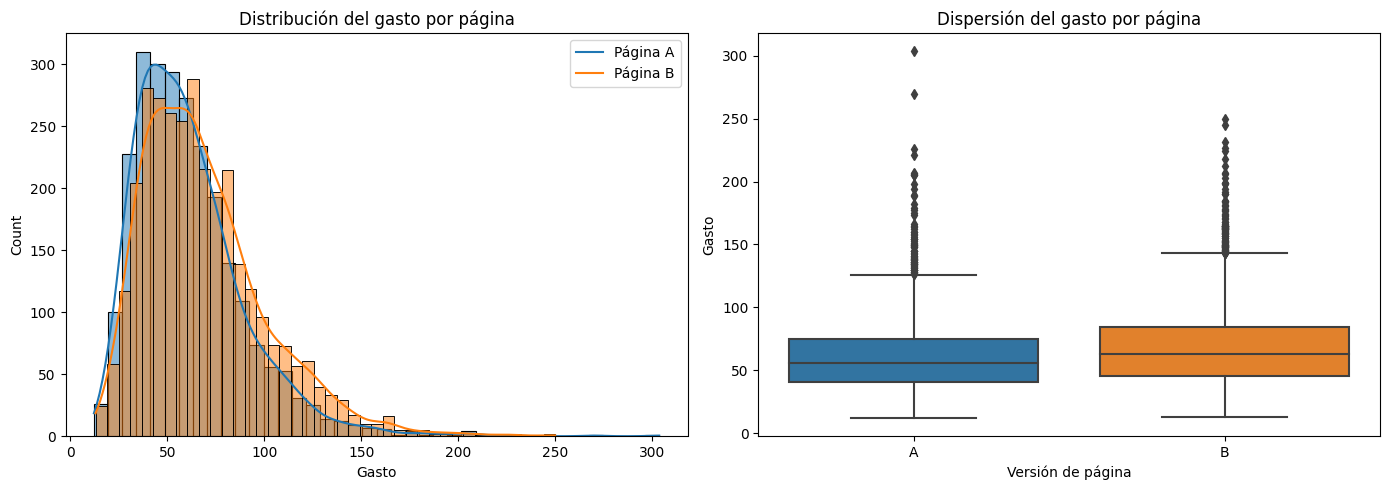

In [126]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#Histogramas
sns.histplot(gasto_A, bins=40, kde=True,color='#1f77b4', alpha=0.5, ax=axes[0])
sns.histplot(gasto_B, bins=40, kde=True, color='#ff7f0e', alpha=0.5, ax=axes[0])

axes[0].set_title('Distribución del gasto por página')
axes[0].set_xlabel('Gasto')
axes[0].legend(['Página A', 'Página B'])

# Boxplot
sns.boxplot(data=df[df['converted'] == 1], x='landing', y='gasto',ax=axes[1])
axes[1].set_title('Dispersión del gasto por página')
axes[1].set_xlabel('Versión de página')
axes[1].set_ylabel('Gasto')
plt.tight_layout()
plt.show()

**Justificación de la prueba estadística seleccionada**

Los histogramas y diagramas de caja muestran que ambas distribuciones presentan asimetría positiva (sesgo hacia la derecha) y numerosos valores atípicos altos, lo que indica que los datos no siguen una distribución perfectamente normal. Sin embargo, considerando el tamaño de las muestras (aproximadamente 2.500 observaciones para A y 3.200 para B), el teorema central del límite permite que la distribución muestral de las medias tienda a aproximarse a una distribución normal, haciendo viable la comparación de medias mediante una prueba t, siempre que las observaciones sean independientes y no exista una influencia excesiva de valores extremos.

Adicionalmente, las observaciones pueden considerarse independientes, dado que cada usuario aparece una sola vez en el conjunto de datos y fue asignado a una única versión de la página.

Finalmente, se seleccionó la prueba t de Welch porque los tamaños de los grupos son diferentes y la prueba de Levene permite evaluar la igualdad de sus varianzas. Este método no requiere asumir varianzas iguales entre los grupos y resulta apropiado para comparar sus medias bajo estas condiciones.

<div class="alert alert-block alert-warning">

Esta justificación es mucho más sólida ahora. Cubres el sesgo y los valores atípicos, el Teorema del Límite Central con grupos de aproximadamente 2,500 a 3,200 usuarios, la independencia y la elección de Welch. Dos refinamientos opcionales: Welch se elige principalmente porque Levene muestra varianzas desiguales, y los diferentes tamaños de grupo solo hacen que ese problema importe más, así que dilo directamente. Además, citas el resultado de Levene antes de que aparezca, por lo que conviene colocar la verificación de Levene antes de esta explicación o mencionar que su resultado se muestra más abajo.

</div>

In [127]:
#Verificar los supuestos estadísticos

#Prueba de levene (test de varianzas)
stat, p_value = levene(gasto_A, gasto_B)

print(f"Estadístico Levene: {stat:.4f}")
print(f"Valor p: {p_value:.2e}")

alpha = 0.05  # umbral de significancia
if p_value < alpha:
    print("Hay evidencia de varianzas diferentes en el gasto registrado de las conversiones de la pagina A con respecto a los de la pagina B.")
else:
    print("No hay evidencia de varianzas diferentes.")


Estadístico Levene: 29.1765
Valor p: 0.0000
Hay evidencia de varianzas diferentes en el gasto registrado de las conversiones de la pagina A con respecto a los de la pagina B.


<div class="alert alert-block alert-warning">

La lógica de Levene y su interpretación son correctas. Sin embargo, el código imprime el valor p con el formato :.2e, mientras que la salida guardada muestra 'Valor p: 0.0000'. Eso significa que la salida mostrada proviene de una ejecución anterior. Usa Kernel > Restart & Run All para que cada salida coincida con el código que envías. Entonces deberías ver el valor p en notación científica.

</div>

In [128]:
#prueba t-test para comparar promedios de gasto entre las versiones de pagina A y B

t_stat, p_value = ttest_ind(gasto_A, gasto_B, equal_var=False)
print(f"Estadístico t: {t_stat:.8f}")
print(f"Valor p: {p_value:.8f}")

Estadístico t: -9.48101092
Valor p: 0.00000000


<div class="alert alert-block alert-warning">

Usar `equal_var=False` (prueba t de Welch) es la elección correcta, y el estadístico t es coherente con tu conclusión. Un valor p impreso como 0.00000000 no le dice nada al lector. Usa notación científica, por ejemplo `f'{p_value:.2e}'`, o repórtalo como 'p < 0.001'.

</div>

### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipótesis nula, ya que el valor p es considerablemente menor que el nivel de significancia 0.05.  Existe evidencia estadísticamente significativa de una diferencia en el gasto promedio de los usuarios que convirtieron, entre las dos versiones de paginas.

**Interpretación de negocio:**  
El estadístico t de valor negativo sugiere que el promedio muestral del gasto relacionado con la pagina A es menor que el promedio muestral registrado de la pagina B. Esto favorece a la versión de pagina B desde la perspectiva del valor económico por usuario convertido para el periodo bajo estudio.

**Comparacion del gasto promedio entre las diferentes versiones de pagina A y B**:



- Página A: 61,09.

- Página B: 68,75.

- Diferencia: 7,66 unidades monetarias.

- Incremento aproximado de B frente a A: 12,54%.

- La comparación cubre únicamente a los usuarios que convirtieron, por lo que no representa el gasto por usuario expuesto.




<div class="alert alert-block alert-warning">

Tu decisión y tu lectura del estadístico t negativo son correctas. También incluiste la diferencia absoluta (7,66), el aumento relativo (12,54 %) y la nota de que esto abarca únicamente a los usuarios convertidos. Algunos detalles por pulir: respalda «considerablemente menor que 0.05» con una cifra como «p < 0.001», usa una sola convención decimal (aquí escribes 61,09, pero en otras partes 0.05), y agrega los acentos que faltan en palabras como «páginas» y «comparación».

</div>

---


## 📈 Paso 3: Comparar la tasa de conversión entre la página A y B

Se evalua si existen difere]ncias estadísticamente significativas en la **tasa de conversión** entre la página A y B, con el fin de identificar qué versión genera **mayor número de usuarios convertidos**.

### Prueba Z para comparar la tasa de conversión entre la página A y B.

**Hipótesis:**
- **Hipótesis nula (H₀):** La tasa de conversión de la página A es igual a la tasa de conversión de la página B
- **Hipótesis alternativa (H₁):** las tasas de conversión de las páginas A y B son diferentes.

In [129]:
# Número de usuarios convertidos por página
conversiones = df.groupby('landing')['converted'].sum()

# Total de usuarios por página
observaciones = df.groupby('landing')['converted'].count()

print("Usuarios convertidos por página:\n\n", conversiones)
print("\nTotal de usuarios por página:\n\n", observaciones)



Usuarios convertidos por página:

 landing
A    2512
B    3194
Name: converted, dtype: int64

Total de usuarios por página:

 landing
A    19982
B    20018
Name: converted, dtype: int64


In [130]:
# Calcular tasas de conversión
tasas_conversion = conversiones / observaciones * 100

print("Tasas de conversión:")
print(tasas_conversion.round(2))

# Diferencia entre las tasas
diferencia = tasas_conversion['B'] - tasas_conversion['A']

print(f"\nDiferencia: {diferencia:.2f} puntos porcentuales")

Tasas de conversión:
landing
A    12.57
B    15.96
Name: converted, dtype: float64

Diferencia: 3.38 puntos porcentuales


In [131]:
# Aplicar prueba
conteos = [conversiones['A'], conversiones['B']]
num_observaciones = [observaciones['A'], observaciones['B']]

z_stat, p_value = proportions_ztest(conteos, num_observaciones)

# Visualizar resultados
print(f"Estadístico : {z_stat}")
print(f"Valor p: {p_value}")

Estadístico : -9.677362674655983
Valor p: 3.7629765627523803e-22


<div class="alert alert-block alert-success">

La prueba Z está configurada correctamente. Los conteos contienen los éxitos y los tamaños de muestra contienen los totales de cada grupo, ambos en orden A, B. El resultado (z = -9.68, p ≈ 3.76e-22) es coherente con tus tasas de 12.57% y 15.96%. El signo negativo es esperable porque A aparece primero y tiene la tasa más baja.

</div>

### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipotesis nula, porque el valor p es significativamente menor que 0.05. La diferencia entre las tasas de conversion de las dos versiones de pagina A y B es estadisticamente significativa.

**Interpretación de negocio:**  
La página B presenta una tasa de conversión de 15.96%, superior al 12.57% registrado por la página A. La diferencia de 3.38 puntos porcentuales para la versión B. El resultado de la prueba Z indica que ésta diferencia es estadísticamente significativa, por lo que es poco probable que se deba únicamente al azar.

La prueba cumple con las condiciones necesarias para su aplicación: los usuarios se consideran independientes, cada uno fue expuesto a una sola versión de la página y ambos grupos cuentan con una cantidad suficiente de conversiones y no conversiones para realizar la comparación.

Desde una perspectiva de negocio, estos resultados sugieren que la página B tiene un mejor desempeño en términos de conversión y podría ser una alternativa prometedora para mejorar los resultados comerciales. Sin embargo, la significancia estadística no garantiza una mayor rentabilidad. Antes de implementar definitivamente esta versión, sería conveniente evaluar factores adicionales como los costos de implementación, los ingresos generados por conversión y el retorno de la inversión.

<div class="alert alert-block alert-warning">

Buen progreso. El 15.96% ahora coincide con tu resultado, y agregaste las condiciones de la prueba y la advertencia de que la significancia estadística no garantiza la rentabilidad. Algunos retoques opcionales: 'La diferencia de 3.38 puntos porcentuales para la versión B.' es una oración incompleta, así que prueba con 'La diferencia es de 3.38 puntos porcentuales a favor de la versión B.' Respalda con números lo de 'enough conversions and non-conversions' (conversiones y no conversiones suficientes); la página A tiene la menor cantidad de conversiones (2,512) y aun así tiene 17,470 no conversiones. Corrige las tildes en palabras como 'hipótesis', 'conversión' y 'estadísticamente', y escribe 'esta diferencia' sin tilde.

</div>

## 🔗 Paso 4: Revisar la relación entre la fuente de tráfico y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.

### Prueba chi cuadrada para evaluar la relación entre fuente de tráfico y la conversión.

**Hipótesis:**
- **Hipótesis nula (H₀):** 'traffic_source'y 'converted', son variables independientes. No existe relación entre la fuente de trafico y la conversion.
- **Hipótesis alternativa (H₁):** Existe una relación entre la fuente de trafico y la conversion.

In [132]:
tabla = pd.crosstab(df["traffic_source"], df["converted"])
print(tabla)

converted           0     1
traffic_source             
Ads             10176  1759
Email            5205   918
Organic         15507  2480
Referral         3406   549


In [133]:
#Calcular tasas de conversión por fuente de trafico
# Agregar total de usuarios y tasa de conversión
resumen_trafico = tabla.copy()
resumen_trafico['Total'] = resumen_trafico.sum(axis=1)
resumen_trafico['Tasa_conversion'] = (resumen_trafico[1] / resumen_trafico['Total'] * 100)

print(resumen_trafico.round(2))

converted           0     1  Total  Tasa_conversion
traffic_source                                     
Ads             10176  1759  11935            14.74
Email            5205   918   6123            14.99
Organic         15507  2480  17987            13.79
Referral         3406   549   3955            13.88


In [134]:
# Aplicar prueba
chi2_stat, p_value, dof, expected = chi2_contingency(tabla)
print(f"Estadístico chi-cuadrado: {chi2_stat:.6f}")
print(f"Valor P: {p_value:.6f}")
print(f"Grados de libertad: {dof}")
print("\nFrecuencias esperadas:\n")
expected_df = pd.DataFrame(expected, index=tabla.index, columns=tabla.columns )
print(expected_df)



Estadístico chi-cuadrado: 8.662109
Valor P: 0.034138
Grados de libertad: 3

Frecuencias esperadas:

converted                 0           1
traffic_source                         
Ads             10232.47225  1702.52775
Email            5249.55405   873.44595
Organic         15421.15445  2565.84555
Referral         3390.81925   564.18075


<div class="alert alert-block alert-success">

Excelente corrección. La prueba de chi-cuadrado ahora se ejecuta únicamente sobre los conteos observados de usuarios convertidos y no convertidos por canal. El resultado es coherente: 3 grados de libertad para una tabla de 4x2, frecuencias esperadas que parecen conteos reales y que están todas muy por encima de 5, un estadístico de 8.66 y p = 0.034138. El valor p que citas en tu conclusión y en tu resumen ejecutivo ahora coincide con este resultado.

</div>

### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipotesis nula, ya que el valor p es menor a 0.05, existe evidencia estadisticamente significativa de una asociación entre la fuente de trafico y la conversión.

**Interpretación de negocio:**  
La prueba Chi-cuadrado evidencia una asociación estadísticamente significativa entre la fuente de tráfico y la conversión (p = 0.034138). Al comparar las tasas individuales, Email presenta el mayor porcentaje de conversión (14.99%), seguido de Ads (14.74%), Referral (13.88%) y Organic (13.79%). Sin embargo, Organic concentra el mayor volumen absoluto de conversiones (2.480), debido a su mayor cantidad de usuarios. Es importante aclarar que las diferencias son modestas y requieren confirmación por pares antes de reasignar el presupuesto.

Desde una perspectiva de negocio, se recomienda evaluar estrategias para fortalecer Email y Ads, sin descuidar Organic por su importante contribución al volumen de conversiones. Se requieren análisis adicionales para determinar si las diferencias entre canales son estadísticamente significativas y evaluar su rentabilidad.



<div class="alert alert-block alert-warning">

Tu decisión de rechazar H₀ es correcta y tu interpretación es cuidadosa. Separas la tasa del volumen y adviertes que aún se necesitan una confirmación por pares y un análisis de rentabilidad. Refinamientos opcionales: p = 0.034 está apenas por debajo de 0.05 y las tasas difieren en aproximadamente 1.2 puntos porcentuales, así que indica explícitamente que la asociación es significativa pero de tamaño modesto. Usa un único formato numérico, ya que escribes '14.99%' pero '2.480'. Además, agrega las tildes que faltan en 'hipótesis', 'estadísticamente' y 'tráfico'.

</div>

## 👤 Paso 5: Revisar la relación entre el tipo de usuario y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.

### Prueba chi cuadrada para evaluar la relación entre el tipo de usuario y la conversión.

**Hipótesis:**
- **Hipótesis nula (H₀):** 'user_type' y 'converted' son variables independientes; no existe relación entre el tipo de usuario y la conversión.
- **Hipótesis alternativa (H₁):** Existe una relación entre el tipo de usuario y la conversión.

In [135]:
tabla2 = pd.crosstab( df["user_type"], df["converted"])
print(tabla2)

converted       0     1
user_type              
Nuevo       22295  3738
Recurrente  11999  1968


In [136]:
# Aplicar prueba
chi2_stat, p_value, dof, expected = chi2_contingency(tabla2)
print(f"Estadístico chi-cuadrado: {chi2_stat:.3f}")
print(f"Valor P: {p_value:.3f}")
print(f"Grados de libertad: {dof}")
print("\nFrecuencias esperadas:")
print(expected)


Estadístico chi-cuadrado: 0.513
Valor P: 0.474
Grados de libertad: 1

Frecuencias esperadas:
[[22319.39255  3713.60745]
 [11974.60745  1992.39255]]


<div class="alert alert-block alert-success">

Excelente trabajo. La prueba de chi-cuadrado sobre la tabla de 2x2 es correcta y el resultado tiene sentido: 1 grado de libertad, chi-cuadrado 0.513, p = 0.474 y frecuencias esperadas muy por encima de 5. Imprimir las frecuencias esperadas permite al lector verificar las condiciones de la prueba. Como extra opcional, indica las tasas de conversión reales para cada tipo de usuario (alrededor de 14.4% para Nuevo y 14.1% para Recurrente) para que el resultado de 'no asociación' sea más tangible.

</div>

### 📝 Conclusión e interpretación

**Decisión:**  
No se rechaza la hipotesis nula, ya que el valor p es mayor a 0.05, no se encontró evidencia estadisticamente significativa para afirmar que existe una asociación entre el tipo de usuario y la conversion.

**Interpretación de negocio:**  
con estos datos no se puede concluir que ser nuevo o recurrente esté relacionado con una mayor probabilidad de conversión.

## 📊 Paso 6: Visualizar los resultados de variables categóricas

Se explora visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:
- la cantidad absoluta de usuarios que convirtieron y no convirtieron,
- la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.

### Relación entre la fuente de tráfico y la conversión

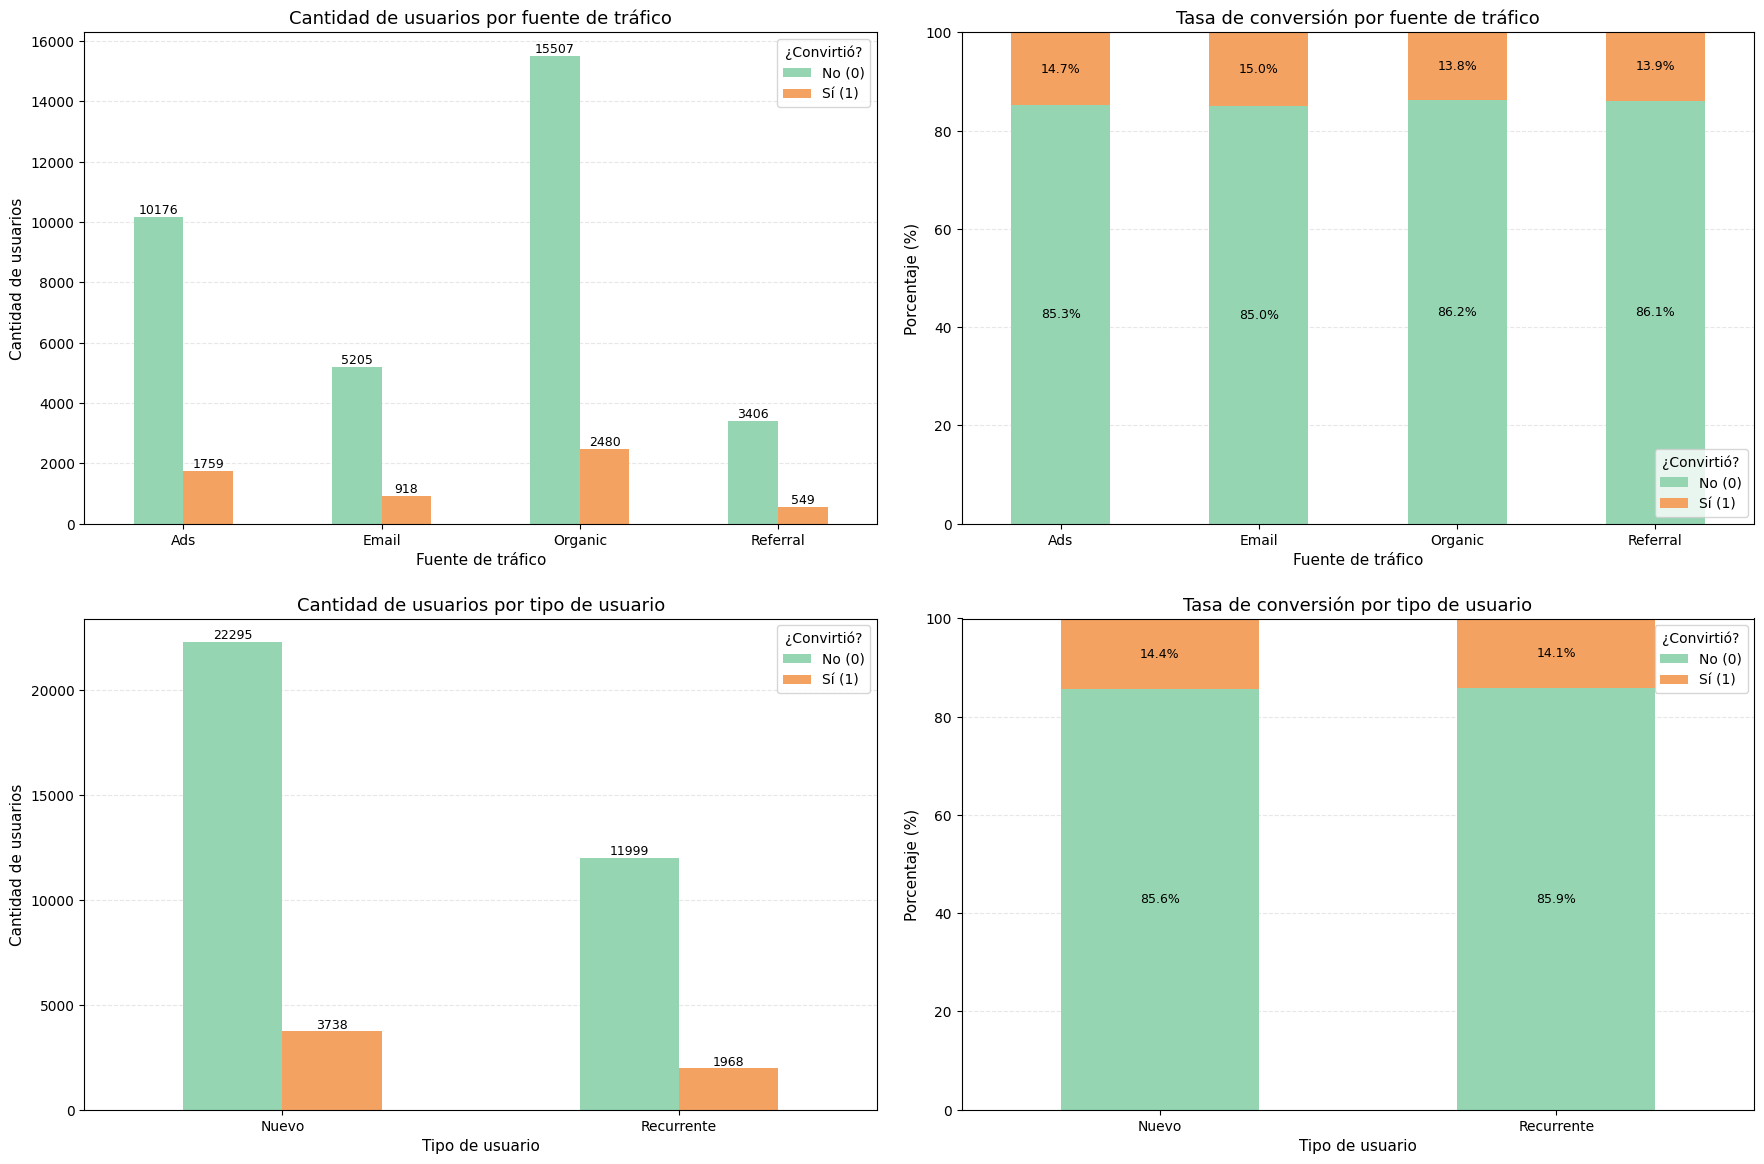

In [137]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Preparar tablas de conteos y porcentajes
conteos_trafico = pd.crosstab(df['traffic_source'], df['converted'])
tasas_trafico = pd.crosstab(df['traffic_source'], df['converted'], normalize='index') * 100

conteos_usuario = pd.crosstab(df['user_type'], df['converted'])
tasas_usuario = pd.crosstab(df['user_type'], df['converted'], normalize='index') * 100

# Garantizar el mismo orden de las categorías: 0 = No, 1 = Sí
conteos_trafico = conteos_trafico.reindex(columns=[0, 1], fill_value=0)
tasas_trafico = tasas_trafico.reindex(columns=[0, 1], fill_value=0)

conteos_usuario = conteos_usuario.reindex(columns=[0, 1], fill_value=0)
tasas_usuario = tasas_usuario.reindex(columns=[0, 1], fill_value=0)

# Colores consistentes: No convirtió / Sí convirtió
colores = ["#95D5B2", "#F4A261"]

# 1. Conteos absolutos por fuente de tráfico
# --------------------------------------------------
conteos_trafico.plot(kind='bar', ax=axes[0, 0], color=colores)

ax1 = axes[0, 0]

ax1.set_title('Cantidad de usuarios por fuente de tráfico', fontsize=13)
ax1.set_xlabel('Fuente de tráfico', fontsize=11)
ax1.set_ylabel('Cantidad de usuarios', fontsize=11)
ax1.legend(title='¿Convirtió?', labels=['No (0)', 'Sí (1)'])

# Agregar etiquetas numéricas sobre las barras
for bar in ax1.patches:
    height = bar.get_height()
    ax1.text(x=bar.get_x() + bar.get_width() / 2,y=height,s=f'{height:.0f}',ha='center',va='bottom',fontsize=9)


# --------------------------------------------------
# 2. Tasas de conversión por fuente de tráfico
# --------------------------------------------------
tasas_trafico.plot(kind='bar', stacked=True, ax=axes[0, 1], color=colores)

ax2 = axes[0, 1]

ax2.set_title('Tasa de conversión por fuente de tráfico', fontsize=13)
ax2.set_xlabel('Fuente de tráfico', fontsize=11)
ax2.set_ylabel('Porcentaje (%)', fontsize=11)
ax2.set_ylim(0, 100)
ax2.legend(
    title='¿Convirtió?',
    labels=['No (0)', 'Sí (1)'],
    loc='lower right'
)

# Mostrar porcentajes dentro de cada segmento
for bar in ax2.patches:
    height = bar.get_height()

    # Obtener la posición central del segmento
    x = bar.get_x() + bar.get_width() / 2

    # Obtener la posición vertical central del segmento
    y = bar.get_y() + height / 2

    ax2.text(
        x=x,
        y=y,
        s=f'{height:.1f}%',
        ha='center',
        va='center',
        fontsize=9
    )


# --------------------------------------------------
# 3. Conteos absolutos por tipo de usuario
# --------------------------------------------------
conteos_usuario.plot(
    kind='bar', ax=axes[1, 0], color=colores
)

ax3 = axes[1, 0]

ax3.set_title('Cantidad de usuarios por tipo de usuario', fontsize=13)
ax3.set_xlabel('Tipo de usuario', fontsize=11)
ax3.set_ylabel('Cantidad de usuarios', fontsize=11)
ax3.legend(title='¿Convirtió?', labels=['No (0)', 'Sí (1)'])

# Agregar etiquetas numéricas sobre las barras
for bar in ax3.patches:
    height = bar.get_height()
    ax3.text(
        x=bar.get_x() + bar.get_width() / 2,
        y=height,
        s=f'{height:.0f}',
        ha='center',
        va='bottom',
        fontsize=9
    )


# --------------------------------------------------
# 4. Tasas de conversión por tipo de usuario
# --------------------------------------------------
tasas_usuario.plot(
    kind='bar', stacked=True, ax=axes[1, 1], color=colores
)

ax4 = axes[1, 1]

ax4.set_title('Tasa de conversión por tipo de usuario', fontsize=13)
ax4.set_xlabel('Tipo de usuario', fontsize=11)
ax4.set_ylabel('Porcentaje (%)', fontsize=11)
ax4.set_ylim(0, 100)
ax4.legend(
    title='¿Convirtió?',
    labels=['No (0)', 'Sí (1)'],
    loc='upper right'
)

# Mostrar porcentajes dentro de cada segmento
for bar in ax4.patches:
    height = bar.get_height()

    x = bar.get_x() + bar.get_width() / 2
    y = bar.get_y() + height / 2

    ax4.text(
        x=x,
        y=y,
        s=f'{height:.1f}%',
        ha='center',
        va='center',
        fontsize=9
    )

# Ajustes generales
for ax in axes.flat:
    ax.tick_params(axis='x', rotation=0)
    ax.grid(axis='y', linestyle='--', alpha=0.3)
    ax.set_axisbelow(True)

fig.tight_layout(pad=2.0)
plt.show()




<div class="alert alert-block alert-warning">

Estos cuatro paneles son una clara mejora. Muestran los conteos y los porcentajes de conversión de ambas variables, con etiquetas de valor, colores consistentes y títulos de leyenda claros, y los números coinciden con tus tablas anteriores. Refinamientos opcionales: la leyenda del panel de tasas por canal todavía cubre parte de la barra de Referral y la del panel de tipo de usuario toca el borde de la barra de Recurrente, por lo que moverlas fuera de los ejes con bbox_to_anchor=(1.02, 1), loc='upper left' solucionaría ambos problemas. Las barras apiladas de 0 a 100% hacen que todos los canales se vean casi idénticos, así que un panel que muestre solo la tasa de conversión con un eje y de aproximadamente 0 a 20 haría visibles las pequeñas diferencias. El código de las etiquetas y la leyenda se repite cuatro veces, y una pequeña función auxiliar lo acortaría.

</div>

✍️ **cantidades absolutas por fuente de tráfico**

La fuente Organic concentra el mayor volumen de usuarios y también el mayor número de conversiones (2.480). Le siguen Ads (1.759), Email (918) y Referral (549). En términos de volumen, Organic es el canal que más conversiones aporta; sin embargo, estas cantidades deben interpretarse considerando que los canales no tienen el mismo número de usuarios expuestos. Por ejemplo, Email tiene la tasa más alta y Organic la más baja, por lo que el ranking por tasa difiere del ranking por volumen, aunque las diferencias son pequeñas.

### Relación entre el tipo de usuario y la conversión

✍️ **Comentario – proporción de conversión por tipo de usuario**

Las tasas de conversión son muy similares entre usuarios nuevos y usuarios recurrentes. La diferencia es reducida y coincide con el resultado de la prueba Chi-cuadrado (p = 0,474), que no encontró una asociación estadísticamente significativa entre el tipo de usuario y la conversión. Por tanto, no se observa una ventaja clara de un grupo sobre el otro.

<div class="alert alert-block alert-success">

Tu lectura de los gráficos por tipo de usuario es clara y correcta. Las tasas son muy similares, y la relacionas con el resultado no significativo de la prueba chi-cuadrado (p = 0,474) sin afirmar que haya ventaja para ninguno de los grupos. Citar las tasas del gráfico (14.4% frente a 14.1%) haría que el punto fuera aún más concreto.

</div>

## 🧩 Paso 7. Insight Ejecutivo para Stakeholders

Se traducen los hallazgos del análisis del experimento A/B en conclusiones accionables para el negocio, enfocadas en **versión de página, conversión, gasto promedio, canales de tráfico y tipo de usuario**.

**Preguntas a responder:**  
- ¿Qué página genera mayor conversión y gasto promedio?  
- ¿Qué canales de tráfico son más efectivos para generar conversiones?  
- ¿Existen diferencias significativas según el tipo de usuario?  
- ¿Qué recomendaciones se pueden tomar para optimizar la estrategia de marketing?


---

### 🌟 Insight Ejecutivo basado en el Experimento A/B

#### 🔍 **Comparación de página (A vs B)**  

**Gasto promedio por usuario que convirtió**

La página B registró un gasto promedio de 68,75 unidades monetarias, frente a 61,09 en la página A. Esto representa una diferencia de 7,66 unidades monetarias y un incremento aproximado del 12,54 % a favor de B. La prueba t de Welch confirmó que esta diferencia es estadísticamente significativa (p < 0,001).

**Tasa de conversión:**

La página B alcanzó una tasa de conversión del 15,96 %, superior al 12,57 % de la página A, lo que representa una diferencia de 3,38 puntos porcentuales. La prueba Z confirmó que esta diferencia es estadísticamente significativa (p = 3,76 × 10⁻²²), por lo que es muy poco probable que se deba únicamente al azar.

**Conclusión de negocio**: La versión B presenta un mejor desempeño en los dos indicadores evaluados: conversión y gasto promedio entre los usuarios que realizaron una conversión. Por lo tanto, se recomienda priorizar su implementación, acompañada de un seguimiento de sus resultados.

Es importante precisar que el gasto promedio se calculó únicamente sobre los usuarios que convirtieron; por tanto, no representa el ingreso promedio por usuario expuesto ni demuestra por sí solo una mayor rentabilidad o retorno de inversión (ROI)

#### 📊 **Segmentación por fuente de tráfico**
La prueba Chi-cuadrado identificó una asociación estadísticamente significativa entre la fuente de tráfico y la conversión (p = 0,034138; 3 grados de libertad). Esto indica que la distribución de conversiones y no conversiones presenta diferencias entre los canales analizados.

Al comparar las tasas de conversión individuales, se observa el siguiente comportamiento:

Email: 14,99 %, la tasa más alta.

Ads: 14,74 %.

Referral: 13,88 %.

Organic: 13,79 %, la tasa más baja.

Por otra parte, Organic registró el mayor volumen absoluto de conversiones (2.480), seguido de Ads (1.759). Esta diferencia está relacionada también con el volumen de usuarios que recibe cada canal, por lo que una mayor cantidad de conversiones no implica necesariamente una mayor efectividad.

**Interpretación:** Email y Ads muestran las tasas de conversión más favorables, mientras que Organic mantiene una contribución importante en términos de volumen. Se recomienda evaluar oportunidades de optimización en Email y Ads, sin descuidar Organic como fuente relevante de adquisición.

Sin embargo, la prueba Chi-cuadrado evalúa la asociación global entre las variables y no permite afirmar que las diferencias entre cada par de canales sean estadísticamente significativas. Antes de reasignar presupuestos, sería conveniente realizar comparaciones adicionales entre canales y evaluar sus costos de adquisición, ingresos y rentabilidad.


#### 📊 **Segmentación por tipo de usuario**
La prueba Chi-cuadrado no encontró evidencia estadísticamente significativa de una asociación entre el tipo de usuario (nuevo o recurrente) y la conversión (p = 0,474).

**Interpretación**: Con la información disponible, no se puede afirmar que los usuarios nuevos o recurrentes tengan una mayor probabilidad de conversión. Por esta razón, se recomienda mantener estrategias comerciales dirigidas a ambos segmentos y continuar monitoreando su comportamiento, evitando priorizar uno sobre otro con base en diferencias que no han sido demostradas estadísticamente.


#### 💡 **Recomendaciones de negocio:** 

1. **Priorizar la página B**: Considerar su implementación debido a su mejor desempeño estadísticamente significativo en conversión y gasto promedio por usuario convertido. Realizar un seguimiento posterior para verificar que los resultados se mantengan.

2. **Optimizar los canales de adquisición**: Evaluar oportunidades de crecimiento en Email y Ads, considerando sus tasas de conversión y su costo de adquisición. Mantener Organic como un canal relevante por su aporte al volumen total de conversiones.

3. **Profundizar en el análisis de canales**: Realizar comparaciones estadísticas por pares y complementar los resultados con métricas de ingresos, costos y retorno de inversión antes de tomar decisiones de redistribución presupuestaria.

4. **Mantener el seguimiento de los segmentos de usuarios**: Continuar evaluando el comportamiento de usuarios nuevos y recurrentes, sin asumir diferencias de conversión que no cuentan con evidencia estadística suficiente.

5. **Monitorear los indicadores de desempeño**: Establecer un seguimiento periódico de la tasa de conversión, el gasto promedio, el volumen de conversiones y la rentabilidad por página y canal, con el propósito de validar la sostenibilidad de los resultados y orientar futuras decisiones comerciales.

<div class="alert alert-block alert-warning">

Muy buen resumen ejecutivo. Las cifras coinciden con tus resultados: el valor p de la fuente de tráfico es 0,034138 con 3 grados de libertad, la tasa de conversión de la página B es 15,96 %, y la comparación del gasto se reporta como p < 0,001. Responde a cada pregunta de negocio y deja claro que el gasto cubre únicamente a los usuarios convertidos y no es ROI, y que las comparaciones por pares entre canales todavía están pendientes. Refinamientos opcionales: indica que la asociación del canal es estadísticamente significativa pero modesta, ya que las tasas van solo del 13,79 % al 14,99 % y, con 40,000 usuarios, incluso diferencias pequeñas pueden resultar significativas. Cita las tasas de conversión reales por tipo de usuario (alrededor de 14,4 % frente a 14,1 %). Añade el punto que falta después de '(ROI)' y considera presentar las cuatro tasas de los canales en una lista con viñetas.

</div>